<a href="https://colab.research.google.com/github/xtianu/UPC_DAPR_2026/blob/main/S2/Exercises/S2_1_Exercises_Data_Visualization_Solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **S2. DATA VISUALIZATION (WITH SOLUTIONS)**

**PRACTICE EXERCISES:**


This notebook contains 3 exercises to practice pandas data handling and seaborn/matplotlib visualization. All exercises use datasets built into seaborn (`sns.load_dataset(...)`), which download automatically the first time you run them.

Each exercise includes the statement followed by a worked solution.


---

## Exercise 1: Handling data and missing values — Penguins dataset

Load the built-in `penguins` dataset from seaborn:

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

Answer the following questions:

a) How many rows and columns does the dataset have? (`.shape`)

b) How many observations have a missing value in the `body_mass_g` column? (use `.isna()`, as seen with the Titanic `Age` column)

c) Create a new dataframe `penguins_filled` where the missing values of `body_mass_g` are replaced with the **mean** of the column (`.fillna()`).

d) Using `.groupby()`, compute the mean `body_mass_g` and `flipper_length_mm` **per species** (`species` column).

e) Filter the dataset to show only penguins of species `"Gentoo"` with `body_mass_g` greater than 5000 (combine two conditions with `&`, as done with the Titanic `Humans`/`Robots` example).

### ✅ Solution

In [ ]:
import seaborn as sns
import pandas as pd

penguins = sns.load_dataset('penguins')
penguins.head()

# a) shape of the dataset
print("Shape:", penguins.shape)

# b) count missing values in 'body_mass_g'
n_missing = penguins.loc[penguins['body_mass_g'].isna() == True].shape[0]
print("Missing body_mass_g values:", n_missing)

# c) create penguins_filled with missing body_mass_g replaced by the mean
penguins_filled = penguins.copy()
penguins_filled['body_mass_g'] = penguins_filled['body_mass_g'].fillna(penguins_filled['body_mass_g'].mean())
print(penguins_filled['body_mass_g'].isna().sum(), "missing values remain")

# d) mean body_mass_g and flipper_length_mm grouped by species
grouped = penguins.groupby(by=['species'])[['body_mass_g', 'flipper_length_mm']].mean()
print(grouped)

# e) filter Gentoo penguins with body_mass_g > 5000
gentoo_heavy = penguins.loc[(penguins['species'] == 'Gentoo') & (penguins['body_mass_g'] > 5000)]
gentoo_heavy


Shape: (344, 7)
Missing body_mass_g values: 2
0 missing values remain
           body_mass_g  flipper_length_mm
species                                  
Adelie     3700.662252         189.953642
Chinstrap  3733.088235         195.823529
Gentoo     5076.016260         217.186992


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
221,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,Male
223,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,Male
224,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,Male
227,Gentoo,Biscoe,46.7,15.3,219.0,5200.0,Male
229,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,Male
...,...,...,...,...,...,...,...
335,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,Male
337,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,Male
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


---

## Exercise 2: Basic and grouped plots — Tips dataset

Load the built-in `tips` dataset from seaborn:

```python
tips = sns.load_dataset('tips')
```

This dataset contains information about restaurant bills: `total_bill`, `tip`, `sex`, `smoker`, `day`, `time`, `size`.

Create the following plots (remember to set `figsize`, add a title with `.set_title()`, and call `plt.show()`):

a) A **scatter plot** of `total_bill` (x-axis) vs `tip` (y-axis).

b) The same scatter plot, but colored by `smoker` status using the `hue` parameter (like the `origin` example with cars).

c) A **linear model plot** (`sns.lmplot`) of `total_bill` vs `tip`, separated by `time` (Lunch/Dinner) using `hue`.

d) A **bar plot** showing the average `tip` for each `day` of the week.

e) A **histogram** (`sns.distplot` or `sns.histplot`) of the `total_bill` column, and mark the **mean** value with a vertical dashed line (`plt.axvline`).

### ✅ Solution

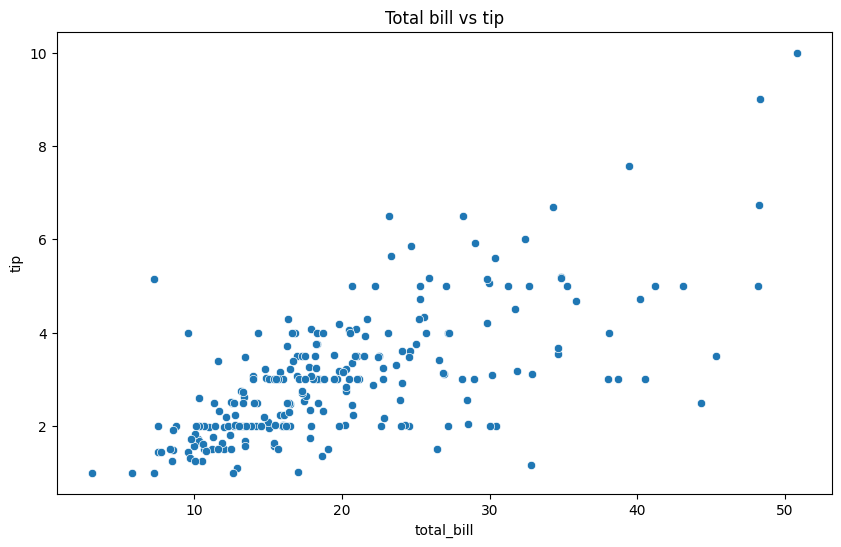

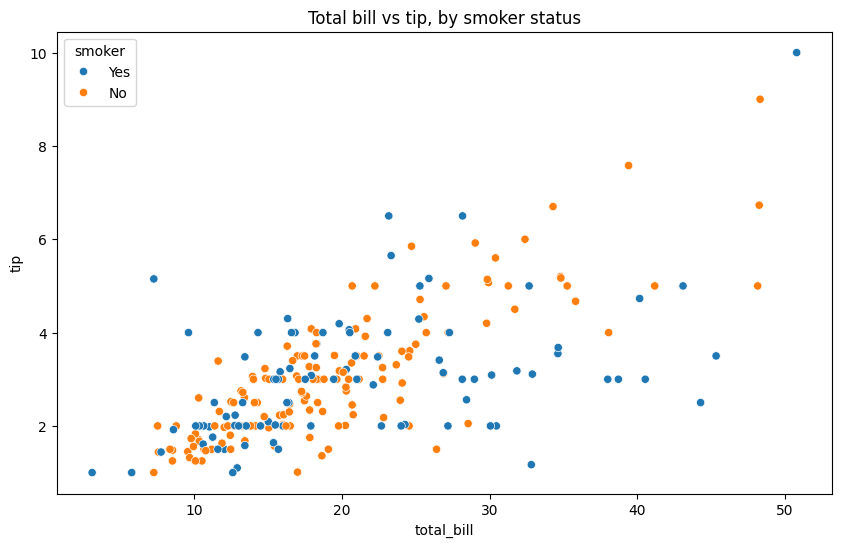

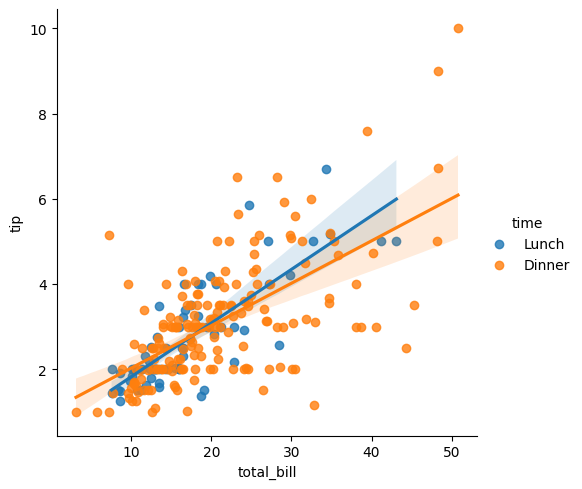

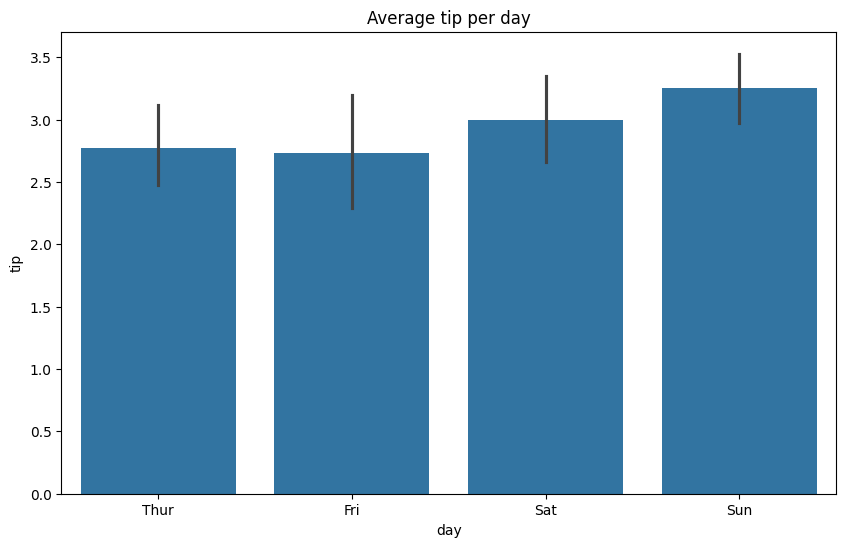

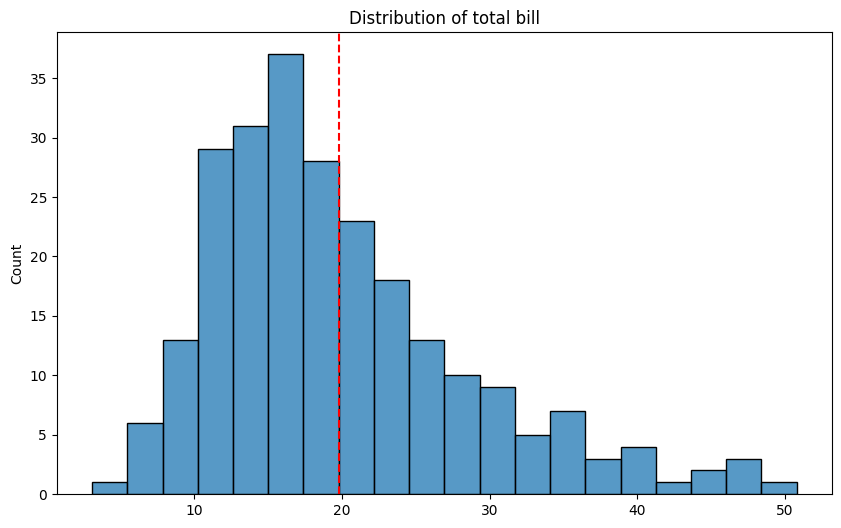

In [ ]:
import matplotlib.pyplot as plt

tips = sns.load_dataset('tips')
tips.head()

# a) scatter plot total_bill vs tip
fig = plt.figure(figsize=(10, 6))
ax = sns.scatterplot(x="total_bill", y="tip", data=tips)
ax.set_title('Total bill vs tip')
plt.show()

# b) same scatter plot colored by 'smoker'
fig = plt.figure(figsize=(10, 6))
ax = sns.scatterplot(x="total_bill", y="tip", hue="smoker", data=tips)
ax.set_title('Total bill vs tip, by smoker status')
plt.show()

# c) lmplot of total_bill vs tip, hue='time'
ax = sns.lmplot(x="total_bill", y="tip", hue="time", data=tips)

# d) bar plot of average tip per day
fig = plt.figure(figsize=(10, 6))
ax = sns.barplot(x="day", y="tip", data=tips)
ax.set_title('Average tip per day')
plt.show()

# e) histogram of total_bill with a vertical line at the mean
mean_bill = tips['total_bill'].mean()

fig = plt.figure(figsize=(10, 6))
ax = sns.histplot(tips["total_bill"].values, bins=20)
plt.axvline(mean_bill, color="r", linestyle="--")
ax.set_title('Distribution of total bill')
plt.show()


---

## Exercise 3: Distributions and multidimensional relationships — Diamonds dataset

Load the built-in `diamonds` dataset from seaborn (it's large, so we take a random sample of 1000 rows to keep the plots fast):

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

This dataset contains information about diamonds: `carat`, `cut`, `color`, `clarity`, `depth`, `table`, `price`, and dimensions `x`, `y`, `z`.

a) Get a statistical summary of the numeric variables with `.describe()`.

b) Create a **histogram** of the `price` variable and mark the mean (dashed line) and the mean ± one standard deviation (two more vertical lines), as done with the `weight` variable of the cars dataset.

c) Create a **joint distribution plot** (`sns.jointplot`) between `carat` and `price`.

d) Create a **pairplot** (`sns.pairplot`) using only the numeric columns `carat`, `depth`, `table`, `price`, colored by the `cut` category with `hue`.

e) Based on the plots above, write one sentence (in a markdown cell or as a Python comment) describing the relationship you observe between `carat` and `price`.

### ✅ Solution

In [ ]:
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
diamonds.head()

# a) statistical summary
diamonds.describe()


,carat,depth,table,price,x,y,z
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,0.827500,61.759700,57.368800,4165.147000,5.80121,5.800870,3.580360
std,0.490193,1.401489,2.303578,4190.104476,1.14740,1.142003,0.700021
min,0.230000,55.200000,53.000000,360.000000,3.89000,3.930000,2.430000
25%,0.410000,61.100000,56.000000,1007.000000,4.74000,4.750000,2.950000
50%,0.710000,61.900000,57.000000,2542.500000,5.74500,5.750000,3.550000
75%,1.080000,62.500000,59.000000,5569.750000,6.60000,6.600000,4.060000
max,2.750000,68.400000,73.000000,18803.000000,9.04000,8.980000,5.490000


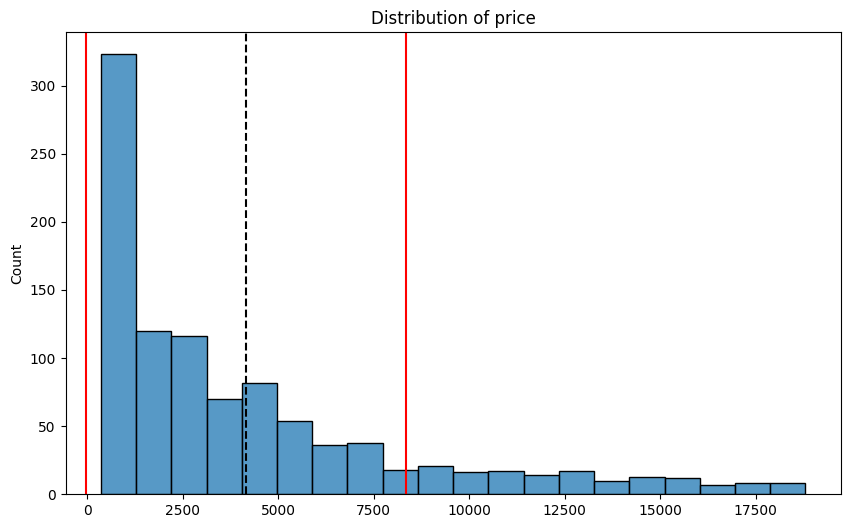

In [ ]:
# b) histogram of 'price' with mean and mean +/- std lines
mean_price = diamonds['price'].mean()
std_price = diamonds['price'].std()

fig = plt.figure(figsize=(10, 6))
ax = sns.histplot(diamonds["price"].values, bins=20)
plt.axvline(mean_price, color="k", linestyle="--")
plt.axvline(mean_price - std_price, color="r", linestyle="-")
plt.axvline(mean_price + std_price, color="r", linestyle="-")
ax.set_title('Distribution of price')
plt.show()


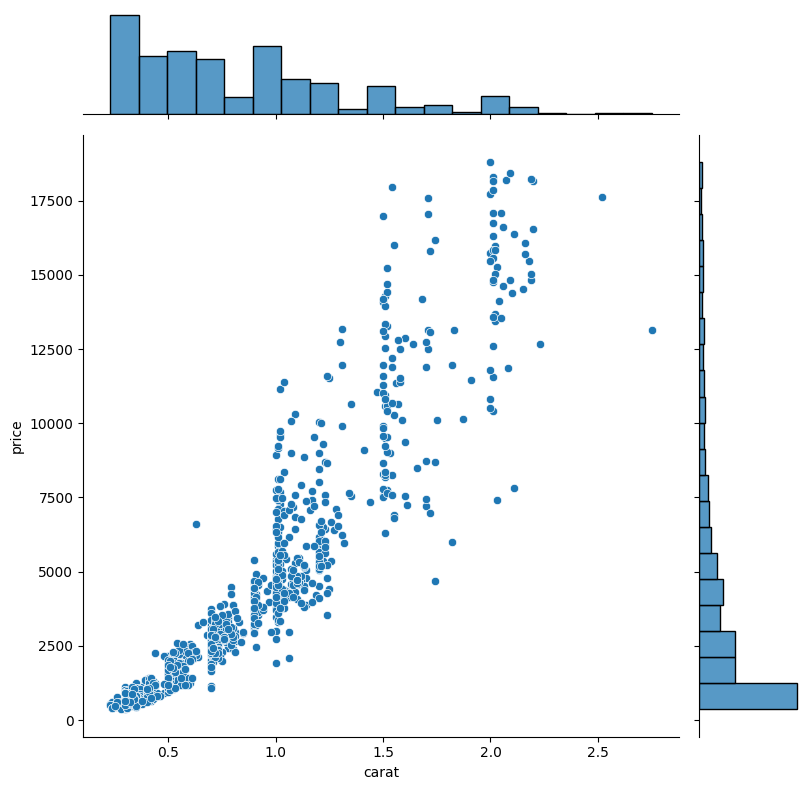

In [ ]:
# c) jointplot between carat and price
ax = sns.jointplot(x='carat', y='price', data=diamonds, height=8)


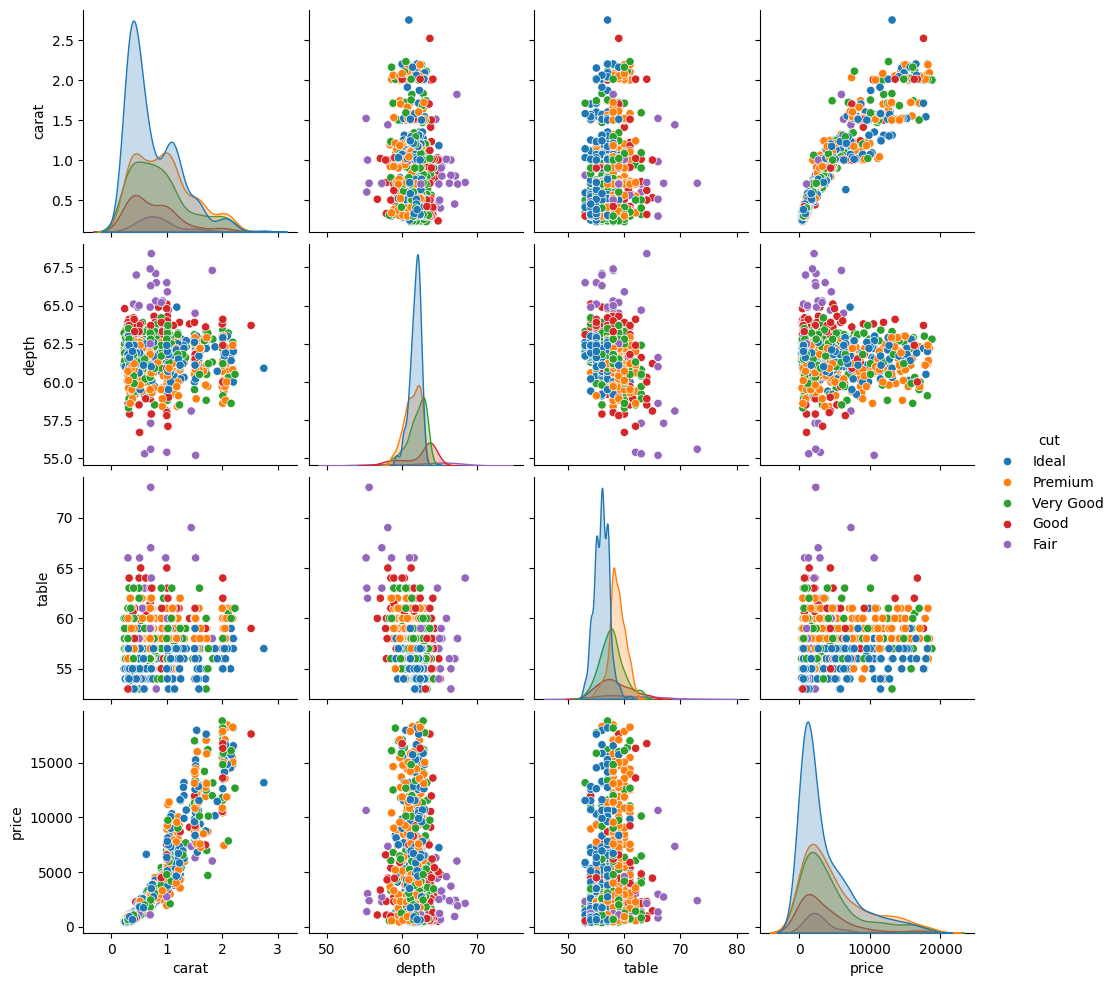

In [ ]:
# d) pairplot of carat, depth, table, price, hue='cut'
cols = ['carat', 'depth', 'table', 'price', 'cut']
sns.pairplot(diamonds[cols], hue='cut')
plt.show()


### e) Interpretation

Looking at the scatter/jointplot between `carat` and `price`, there is a clear **positive, non-linear relationship**: as `carat` (the diamond's weight) increases, `price` increases sharply, and the spread of prices also grows for larger carat values — heavier diamonds are consistently more expensive, and price grows faster than carat itself.